In [1]:
import matplotlib
import matplotlib.pylab as pylab
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import scipy.stats as stats
import os

# Practical Session Activities (Q2)

**Kysil Oleh 50% Petrishka Valeriia 50%**

Target `cnt`

## 4.1 EDA and data preprocessing

### 4.1.A EDA and data preprocessing for selected characteristics

In [4]:
from pathlib import Path

src_dir = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
dataset_dir = src_dir.parent / "dataset"
day_df = pd.read_csv(dataset_dir / "day.csv", sep=",")
hour_df = pd.read_csv(dataset_dir / "hour.csv", sep=",")
for name, frame in {"day": day_df, "hour": hour_df}.items():
    print(name, frame.shape)
    display(frame.head())

day (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


hour (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [5]:
day_df.info()
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Colum

In [6]:
print(day_df.isna().sum())
print(hour_df.isna().sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [7]:
print(day_df.duplicated().sum())
print(hour_df.duplicated().sum())

0
0


## Univariate analysis

### Continuous attributes

In [9]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [11]:
def describe_numeric(df, col, unit=""):
    s = df[col].dropna()
    
    fig,axes=plt.subplots(1, 2, figsize = (12, 4))
    sns.histplot(s, bins=40, ax=axes[0])
    axes[0].axvline(s.mean(), color="red", linestyle="--", label="mean")
    axes[0].axvline(s.median(), color="black", linestyle=":", label="median")
    axes[0].set_title(f"{col}: histogram")
    axes[0].legend()
    
    stats.probplot(df[col], dist="norm", plot=plt)
    axes[1].set_title(f"{col}: boxplot")
    
    plt.tight_layout()
    plt.show()

    print(f"{col}\nSkewness: ", df[col].skew(), "\nKurtosis: ", df[col].kurtosis())

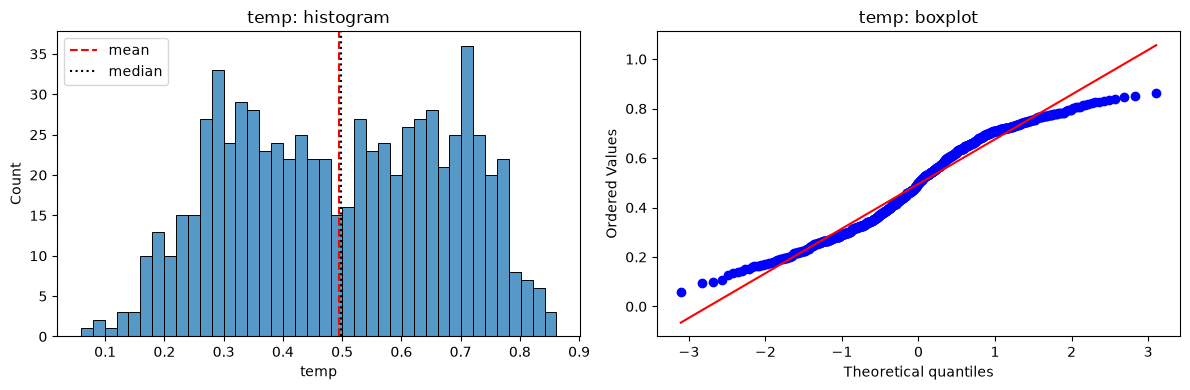

temp
Skewness:  -0.054520964760408276 
Kurtosis:  -1.1188641545735662


In [14]:
describe_numeric(day_df, 'temp')

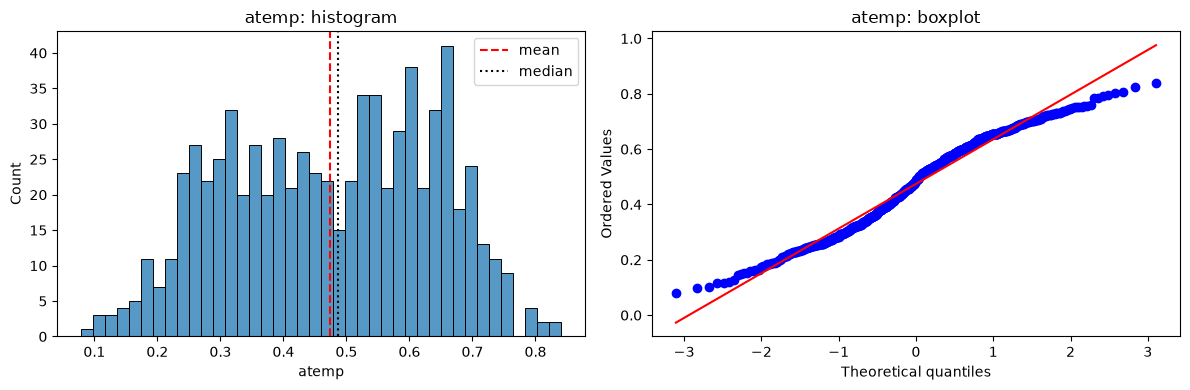

atemp
Skewness:  -0.13108804205446 
Kurtosis:  -0.9851305305195086


In [15]:
describe_numeric(day_df, 'atemp')

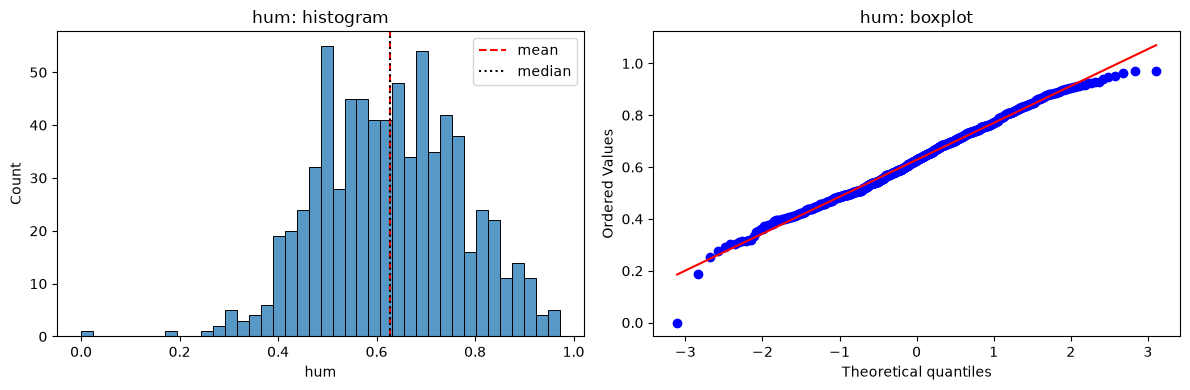

hum
Skewness:  -0.06978343399095213 
Kurtosis:  -0.06453013469388669


In [16]:
describe_numeric(day_df, 'hum')

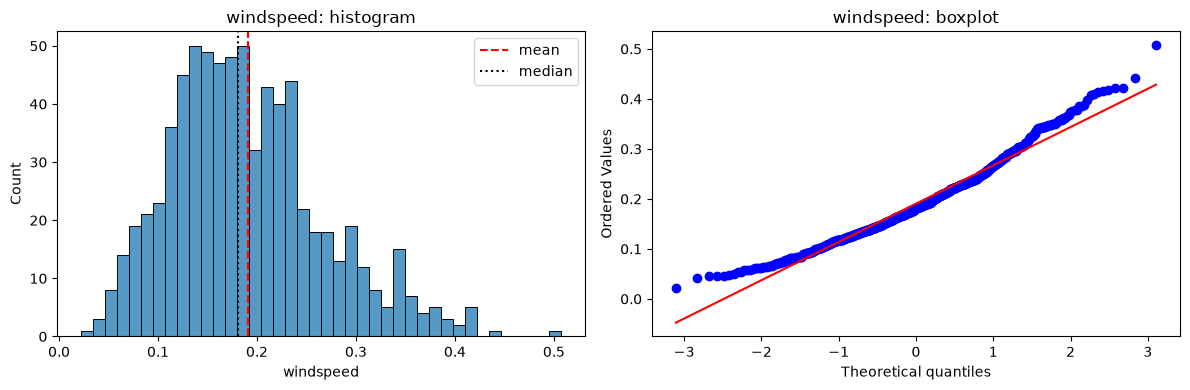

windspeed
Skewness:  0.6773454211095378 
Kurtosis:  0.4109222677315354


In [17]:
describe_numeric(day_df, 'windspeed')

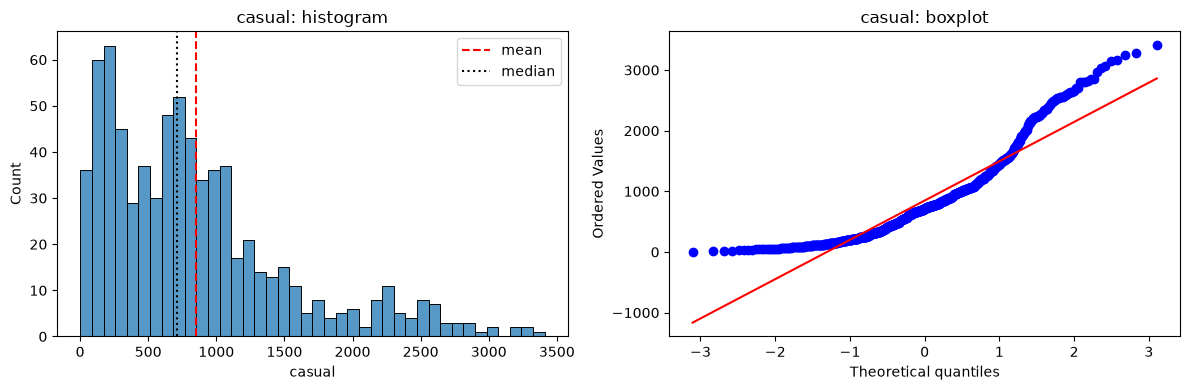

casual
Skewness:  1.2664540319434734 
Kurtosis:  1.3220743270907955


In [28]:
describe_numeric(day_df, 'casual')

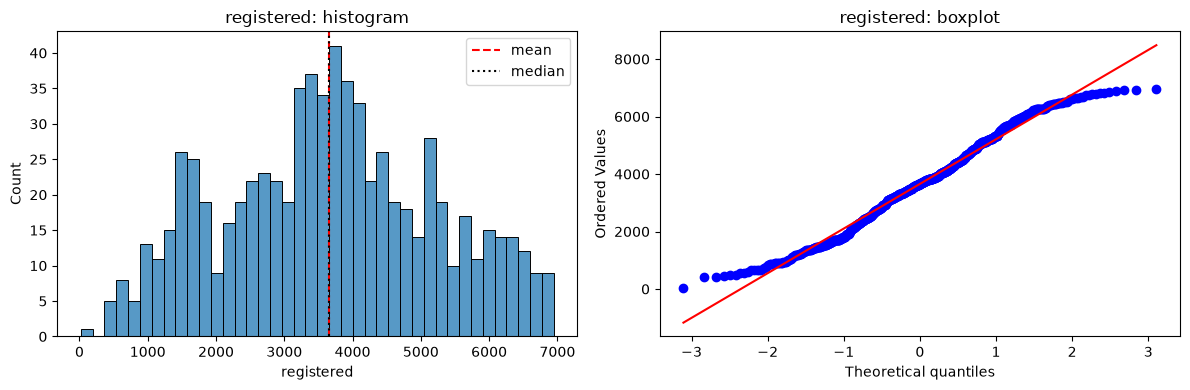

registered
Skewness:  0.04365877988903687 
Kurtosis:  -0.7130971385525173


In [29]:
describe_numeric(day_df, 'registered')

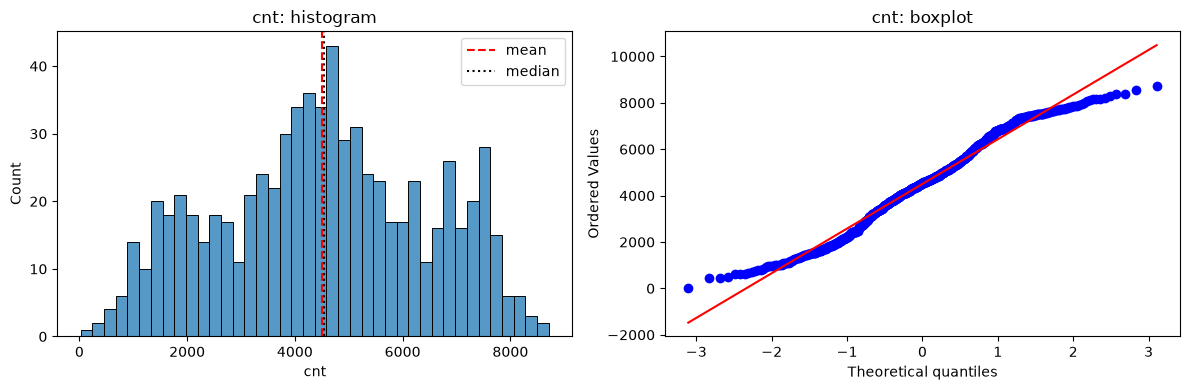

cnt
Skewness:  -0.04735278011900183 
Kurtosis:  -0.8119223847191548


In [27]:
describe_numeric(day_df, 'cnt')

### Categorical attributes

In [20]:
day_df["season"].value_counts()

season
3    188
2    184
1    181
4    178
Name: count, dtype: int64

In [21]:
day_df["yr"].value_counts()

yr
1    366
0    365
Name: count, dtype: int64

In [22]:
day_df["mnth"].value_counts()

mnth
1     62
3     62
5     62
7     62
8     62
10    62
12    62
4     60
6     60
9     60
11    60
2     57
Name: count, dtype: int64

In [24]:
day_df["weekday"].value_counts()

weekday
6    105
0    105
1    105
2    104
3    104
4    104
5    104
Name: count, dtype: int64

In [25]:
day_df["weathersit"].value_counts()

weathersit
1    463
2    247
3     21
Name: count, dtype: int64

In [31]:
day_df["holiday"].value_counts()

holiday
0    710
1     21
Name: count, dtype: int64

In [32]:
day_df["workingday"].value_counts()

workingday
1    500
0    231
Name: count, dtype: int64

## Bivariate analysis

### Continuous - continuous

In [37]:
continuous_columns=["temp","atemp","hum","windspeed","casual", "registered"]
#categorical_columns=["classDuty","Manufacturer","firmware_version","vendor"]

eda_df=day_df.copy()
eda_df["dteday"]=pd.to_datetime(eda_df["dteday"],format="mixed",errors="coerce")

eda_df.shape

(731, 16)

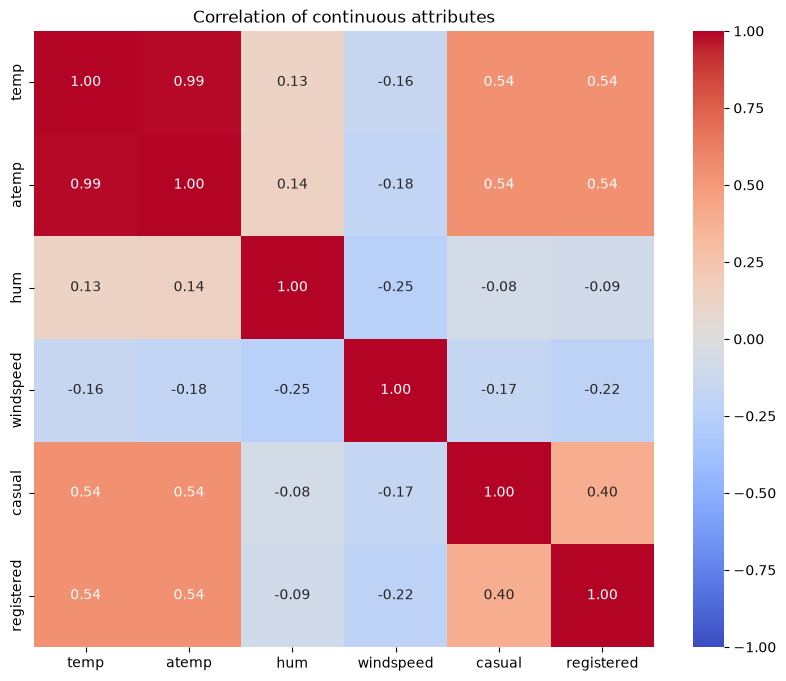

In [38]:
fig,axes=plt.subplots(figsize=(10,8))
sns.heatmap(day_df[continuous_columns].corr(method="pearson"),annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1,ax=axes)
axes.set_title("Correlation of continuous attributes")

plt.show()

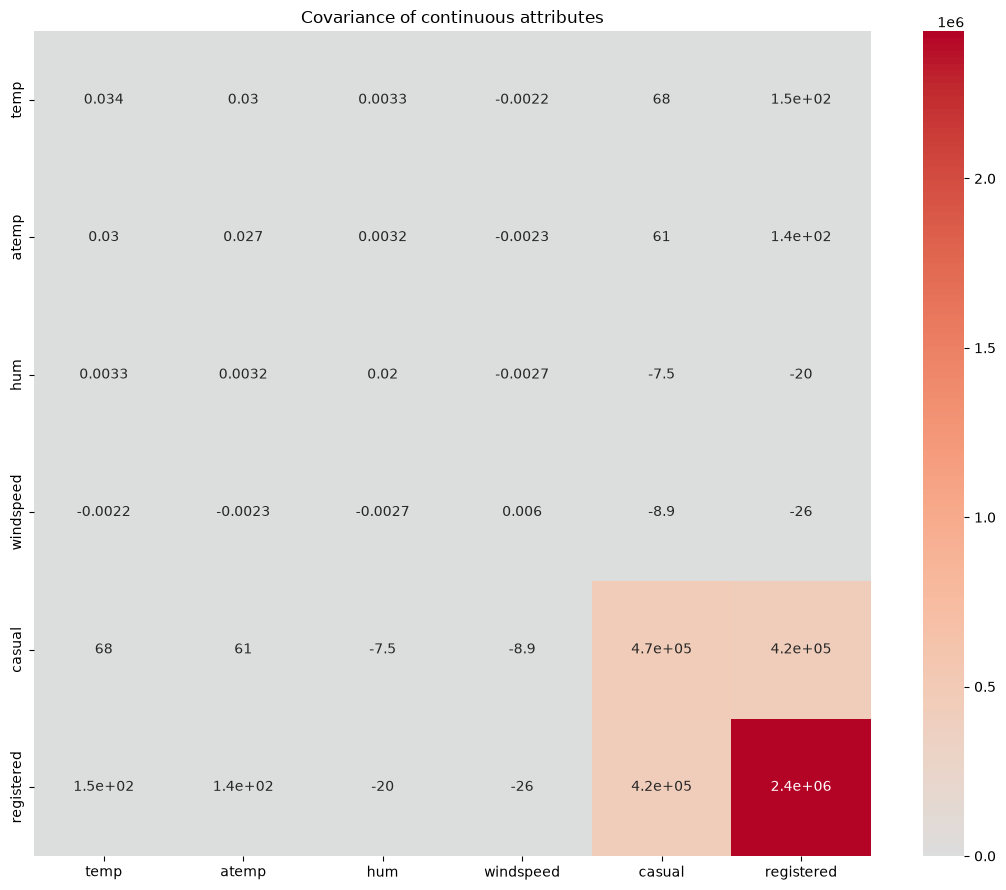

In [39]:
fig,ax=plt.subplots(figsize=(11,9))
sns.heatmap(eda_df[continuous_columns].cov(),annot=True,fmt=".2g",cmap="coolwarm",center=0,ax=ax)
ax.set_title("Covariance of continuous attributes")
plt.tight_layout()
plt.show()

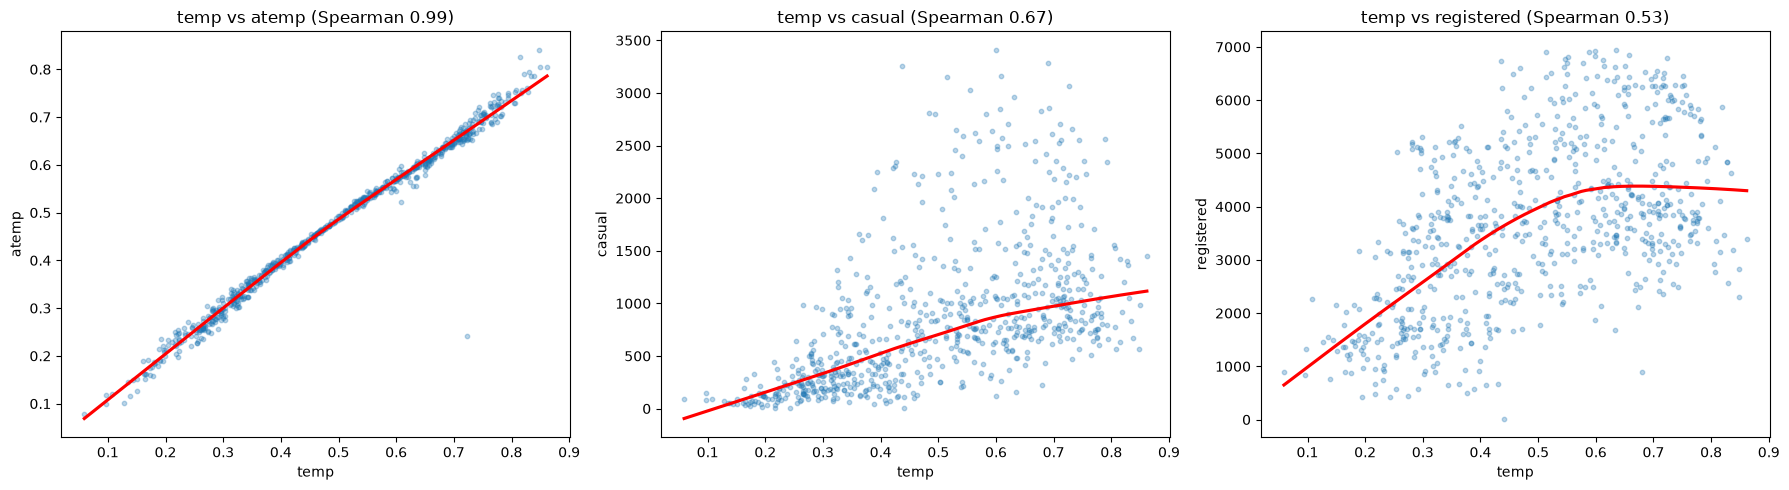

In [47]:
plot_pairs=[("temp","atemp",eda_df),("temp","casual",eda_df),("temp","registered",eda_df)]

fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,(x,y,frame) in zip(axes,plot_pairs):
    sample=frame.sample(min(3000,len(frame)),random_state=42)
    sns.regplot(data=sample,x=x,y=y,ax=ax,lowess=True,scatter_kws={"alpha":0.3,"s":10},line_kws={"color":"red"})
    ax.set_title(f"{x} vs {y} (Spearman {frame[x].corr(frame[y],method='spearman'):.2f})")
    
plt.tight_layout()
plt.show()

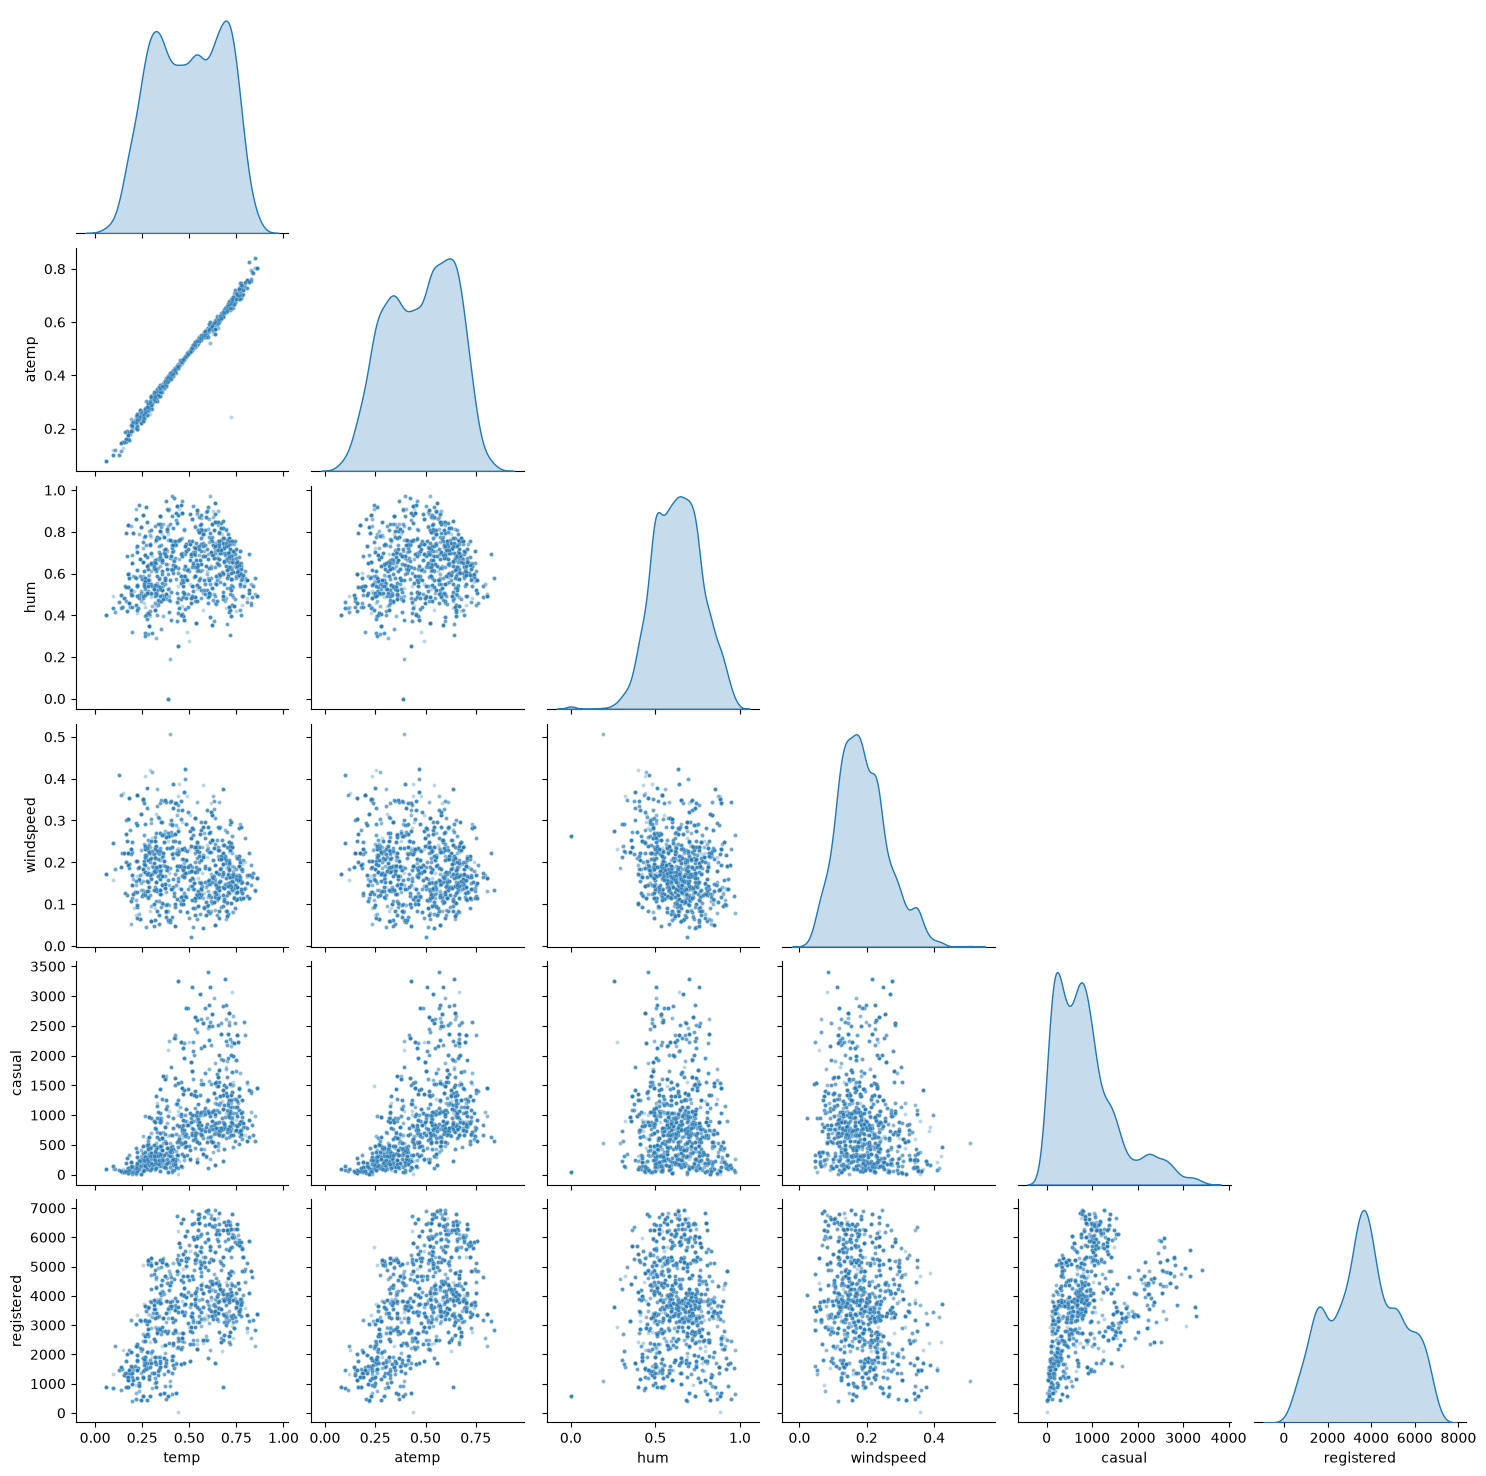

In [50]:
sns.pairplot(eda_df[continuous_columns].sample(3000,random_state=42,replace=True),corner=True,diag_kind="kde",plot_kws={"alpha":0.3,"s":8})
plt.show()